# <span style="color:darkblue"> Lecture 20: Text Analysis </span>

<font size = "5">

Intro text analysis

https://www.youtube.com/watch?v=IRKDrrzh4dE

# <span style="color:darkblue"> I. Setup Working Environment </span>

In [1]:

# Import SK-Learn library for machine learning functions
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS 
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split



# Import standard data analysis packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import Kmenas
from sklearn.cluster import MiniBatchKMeans

import faiss


# <span style="color:darkblue"> II. Data </span>

<font size = "5">

We will analyze a dataset on Amazon Reviews

https://www.kaggle.com/datasets/yasserh/amazon-product-reviews-dataset/data


In [2]:
data = pd.read_csv("data_raw/amazon_reviews.csv")

len(data)


1597

<font size = "5">

Check features

In [3]:
data.columns

Index(['id', 'asins', 'brand', 'categories', 'colors', 'dateAdded',
       'dateUpdated', 'dimension', 'ean', 'keys', 'manufacturer',
       'manufacturerNumber', 'name', 'prices', 'reviews.date',
       'reviews.doRecommend', 'reviews.numHelpful', 'reviews.rating',
       'reviews.sourceURLs', 'reviews.text', 'reviews.title',
       'reviews.userCity', 'reviews.userProvince', 'reviews.username', 'sizes',
       'upc', 'weight'],
      dtype='object')

<font size = "5">

Check text

In [4]:
reviews = data["reviews.text"]

<font size = "5">

Check rating

(array([ 42.,   0.,  34.,   0.,   0., 124.,   0., 236.,   0., 741.]),
 array([1. , 1.4, 1.8, 2.2, 2.6, 3. , 3.4, 3.8, 4.2, 4.6, 5. ]),
 <BarContainer object of 10 artists>)

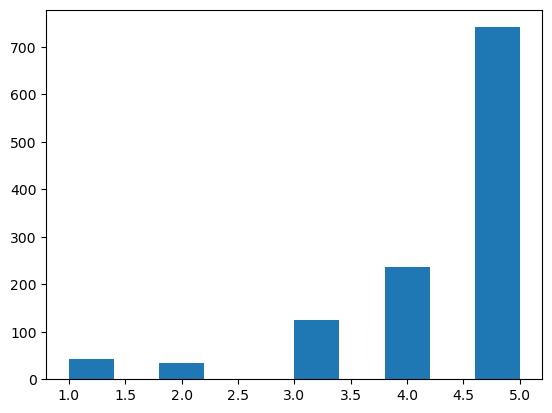

In [5]:
plt.hist(x = data["reviews.rating"])


<font size = "5">

Filter non-missing ratings data

- 26% missing data!
- Could generate selection bias in reviews

In [6]:
# Check for missing values
# A lot of reviews are missing review data
missing_values = data["reviews.rating"].isnull().sum()
percent_missing = missing_values /len(data)
print(percent_missing)

# Extract non-missing data
data_nonmissing = data[data["reviews.rating"].notnull()]

0.2629931120851597


# <span style="color:darkblue"> III. Bag of Words </span>


<font size = "5">

Stop words

- Commonly used words
- Available for different languages



In [9]:
# First ten English stop words
list(ENGLISH_STOP_WORDS)[0:100]

['same',
 'however',
 'whereas',
 'must',
 'everything',
 'fifty',
 'describe',
 'during',
 'for',
 'as',
 'first',
 'other',
 'name',
 'not',
 'own',
 'three',
 'con',
 'eg',
 'ten',
 'you',
 'in',
 'hereby',
 'thereby',
 'four',
 'system',
 'will',
 'along',
 'can',
 'once',
 'ours',
 'whither',
 'but',
 'on',
 'thus',
 'also',
 're',
 'afterwards',
 'wherever',
 'elsewhere',
 'nothing',
 'five',
 'through',
 'whenever',
 'anyhow',
 'had',
 'go',
 'cry',
 'via',
 'otherwise',
 'amoungst',
 'toward',
 'us',
 'beside',
 'alone',
 'are',
 'somewhere',
 'hereupon',
 'without',
 'six',
 'we',
 'this',
 'amongst',
 'almost',
 'one',
 'although',
 'here',
 'becomes',
 'among',
 'could',
 'whole',
 'while',
 'do',
 'noone',
 'twelve',
 'few',
 'call',
 'everywhere',
 'with',
 'top',
 'part',
 'would',
 'seemed',
 'so',
 'besides',
 'often',
 'too',
 'several',
 'which',
 'due',
 'of',
 'side',
 'cant',
 'at',
 'upon',
 'than',
 'put',
 'enough',
 'mill',
 'latterly',
 'only']

<font size = "5">

Create custom stop words

In [16]:
# Here we added Python to the list of stop words
custom_stop_words = list(ENGLISH_STOP_WORDS) + ["Python"]

# You can also create your own list
# custom_stop_words = ["and","or","how"]


<font size = "5">

Count vectorizer

- Check for distinct words across all reviews
- Remove any stop words
- ```min_df``` is used to filter out words depending <br>
on how often they occur. For example, ```min_df=3``` <br>
only keeps words if they are mentioned at least 3 times

In [13]:
word_model = CountVectorizer(min_df=1,
                       stop_words=custom_stop_words)
word_model.fit(reviews)

CountVectorizer(stop_words=['same', 'however', 'whereas', 'must', 'everything',
                            'fifty', 'describe', 'during', 'for', 'as', 'first',
                            'other', 'name', 'not', 'own', 'three', 'con', 'eg',
                            'ten', 'you', 'in', 'hereby', 'thereby', 'four',
                            'system', 'will', 'along', 'can', 'once', 'ours', ...])

<font size = "5">

Check Vocabulary

- Check in VS-Code Data Viewer
- You can use preliminary findings to decide whether <br>
to add more stop words

In [14]:
# Extract words in vocabulary and frequency
vocabulary = word_model.vocabulary_

# Convert to dataframew
frequency_words  = pd.DataFrame(vocabulary.items(),
                                columns=['Word', 'Frequency'])
                                
# Display sorted dataset                                
frequency_words.sort_values(by = "Frequency",ascending=False)

,Word,Frequency
4309,zumi,6194
4474,zooming,6193
4856,zoom,6192
5496,zombies,6191
2692,zippy,6190
...,...,...
1449,07,4
3398,04,3
484,000s,2
494,000,1


<font size = "5">

Create a dataset counting which words are used <br>
per review

- Each row is a different review
- Each column is a ${0,1}$ indicator on whether that <br>
word was mentioned
- Huge matrix!!

In [15]:
# Create X matrix
X = word_model.transform(reviews)

# Check dimension of X matrix
np.shape(X)

X_dataframe = pd.DataFrame(X)

<font size = "5">

Try it yourself!

Create a bag of words for the column "review.title".

- What are the most common words?



In [23]:
# Write your own code

#???? not correct fix later

# Check for missing values
# A lot of reviews are missing review data
missing_vals = data["reviews.title"].isnull().sum()
percent_miss = missing_vals /len(data)
print(percent_miss)

# Extract non-missing data
reviews_title = data[data["reviews.title"].notnull()]

custom_stop_words = list(ENGLISH_STOP_WORDS) + ["Python"]

new_model = CountVectorizer(min_df=1,
                       stop_words=custom_stop_words)
new_model.fit(reviews_title)

# Extract words in vocabulary and frequency
vocab = new_model.vocabulary_

# Convert to dataframew
frequency_title  = pd.DataFrame(vocab.items(),
                                columns=['Word', 'Frequency'])
                                
# Display sorted dataset                                
display(frequency_title.sort_values(by = "Frequency",ascending=False))

# Create X matrix
title = word_model.transform(reviews_title)

# Check dimension of X matrix
np.shape(title)

title_dataframe = pd.DataFrame(title)

0.010644959298685034


/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:408: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['python'] not in stop_words.
  warnings.warn(


,Word,Frequency
26,weight,26
22,userprovince,25
23,username,24
21,usercity,23
25,upc,22
20,title,21
19,text,20
18,sourceurls,19
24,sizes,18
13,reviews,17


# <span style="color:darkblue"> IV. Sentiment Analysis </span>

<font size = "5">
Sentiment analsys uses words to predict user ratings. <br>


- In this case we have ratings labels
- We'll use the data with nonmissing labels


In [24]:
# Write your own code

text = data_nonmissing["reviews.text"]
y    = data_nonmissing["reviews.rating"]

text_train, text_test, y_train, y_test = train_test_split(text, y,
                                                    random_state=0)

<font size = "5">

Extract vectorized X

In [30]:
# Create X matrix
word_model_train = CountVectorizer(min_df=1,
                       stop_words=custom_stop_words)
word_model_train.fit(text_train)
X_train = word_model_train.transform(text_train)

# Check dimension of X matrix
np.shape(X)

/opt/anaconda3/lib/python3.12/site-packages/sklearn/feature_extraction/text.py:408: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['python'] not in stop_words.
  warnings.warn(


(1597, 6195)

<font size = "5">

We can compress the data using <br>
truncated singular value decomposition (SVD)

- This is an alternative to PCA that is better suited <br>
for sparse, binary data like text

In [31]:
svd = TruncatedSVD(n_components=3,random_state=42);
svd.fit(X_train)
X_svd_train = svd.transform(X_train)
np.shape(X_svd_train)

(882, 3)

[Text(0.5, 0, 'First Principal Component'), Text(0, 0.5, 'Product Rating')]

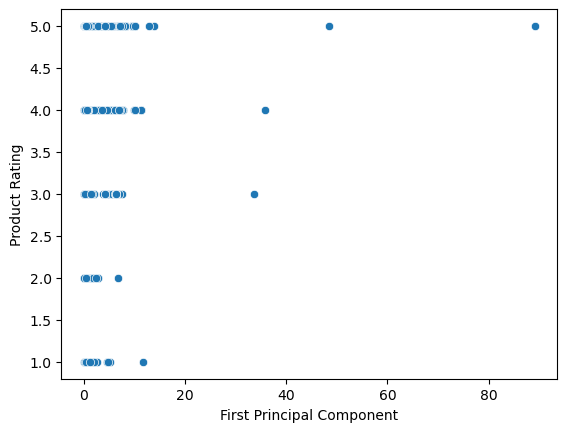

In [32]:
# Hue is used to color
ax = sns.scatterplot(x = X_svd_train[:,0],
                     y = y_train)
ax.set(xlabel='First Principal Component',
       ylabel='Product Rating')


<font size = "5">

Try it yourself!

Create a machine learning pipeline

- Run a support vector machine regression to predict user ratings
- What is the out-of-sample performance on the test data?
- Use your data to predict reviews that were missing
- How does the distribution of missing to non-missing reviews compare?



In [18]:
# Write your own code





<font size = "5">

Try it yourself!

- What happens if you change the minimum frequency of words <br>
and/or change the number of components?

In [19]:
# Write your own code



